# A/B тест новой формы оплаты ЖКХ с упрощённым заполнением реквизитов

**Задача:** Определить, стоит ли распространять новую форму оплаты ЖКХ с упрощённым заполнением реквизитов на всех пользователей.
Проанализировать результаты  A/B теста и подготовить рекомендацию для продуктовой команды. 

**Данные**: Excel-файл с информацией о пользователях (A/B группа, тип устройства, город) и попытки оплаты ЖКХ за период теста (воронка по шагам).

**Дизайн по условию:** 

Гипотеза: Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.

Ключевая метрика: Конверсия из открытия формы оплаты в успешную оплату.

Длительность теста: 30 дней (1-30 апреля 2024).


**План исследования:**
1. Разведочный анализ данных (EDA).
2. Расчет ключевой метрики.
3. Статистическая проверка гипотезы по ключевой метрике.
4. Результаты и рекомендации.

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">1. Разведочный анализ данных (EDA)</b>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Выполним загрузку данных с из Excel: лист 1 - данные о пользователях, лист 2 - о платежах.</p>
</div>

In [1]:
import pandas as pd

file_path = "dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx"

users = pd.read_excel(file_path, sheet_name=0)
payments = pd.read_excel(file_path, sheet_name=1)

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Проведем предварительный анализ и предобработку данных.</p>
    <p style="font-size: 14px;">Для начала проверим типы данных, структуру таблиц и наличие null в каждой из таблиц.</p>
    <ul>
        <li style="font-size: 14px;">users</li>
    </ul>
</div>

In [2]:
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [3]:
users.info()

# нашли пропуски в столбцах group и city

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB


In [4]:
users[users['group'].isna()]

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


In [5]:
users.user_id.nunique()

# число уникальных user_id = число записей в таблице

1504

In [6]:
# доля пользователей с A/B группой
users.group.value_counts(normalize=True)

group
A    0.500333
B    0.499667
Name: proportion, dtype: float64

In [7]:
#  только пользователи с известной A/B группой
users = users.dropna(subset=['group'])
users.shape

(1503, 5)

In [8]:
# проверяем возраст: для поиска аномалий используем диапазон от 0 до 100 лет
invalid_age = (users['age'] < 0) | (users['age'] > 100)
users[invalid_age]


,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [9]:
# проверяем, есть ли попытки оплаты у пользователей с некорректным возрастом
payments[payments['user_id'].isin(users.loc[invalid_age, 'user_id'])].shape[0]

# платежей, поэтому обработка возраста не повлияет на конверсию


0

In [10]:
# заменяем некорректный возраст на пропуски, самих пользователей сохраняем
users['age'] = users['age'].mask(invalid_age)
users.loc[invalid_age, ['user_id', 'age']]


,user_id,age
1501,9002,NaN
1502,9003,NaN


In [11]:
users.groupby('group').agg(
    min_user_id=('user_id', 'min'),
    max_user_id=('user_id', 'max'),
    mean_user=('user_id', 'mean'),
    n_users=('user_id', 'nunique'),
)
     

,min_user_id,max_user_id,mean_user,n_users
group,,,,
A,1001,9004,1395.785904,752
B,1751,9003,2134.657790,751


In [12]:
users[users['group'] == 'A'] \
    .sort_values('user_id') \
    .tail(10)

,user_id,group,age,city,device_type
742,1743,A,30.0,Москва,ios
743,1744,A,40.0,СПб,ios
744,1745,A,31.0,Москва,android
745,1746,A,28.0,СПб,ios
746,1747,A,36.0,Москва,ios
747,1748,A,38.0,Москва,ios
748,1749,A,31.0,СПб,android
749,1750,A,23.0,Москва,android
1501,9002,A,NaN,СПб,android
1503,9004,A,30.0,NaN,android


In [13]:
users[users['group'] == 'B'] \
    .sort_values('user_id') \
    .tail(5)

# группа А: диапазон id 1001 - 1750 + 2 выброса
# группа B: 1751 - 2500 + 1 выброс

,user_id,group,age,city,device_type
1496,2497,B,33.0,Москва,android
1497,2498,B,28.0,СПб,ios
1498,2499,B,42.0,Москва,ios
1499,2500,B,39.0,Москва,ios
1502,9003,B,NaN,Регион,ios


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">В таблице каждая строка - уникальный пользователь, нет дублей по user_id.</p>
     <p style="font-size: 14px;">Выявили 1 пользователя без указанной A/B группы. Не будем учитывать его дальше в анализе. Также нашли 1 пользователя без city, остуствие города не является причиной для исключения его из анализа текущего эксперимента, так как эксперимент не связан с городом пользователя. Далее в анализе участвует <b>1503 пользователя </b> с известной A/B  группой.</p>
    <p style="font-size: 14px;">В контрольной группе A и в тестовой B находится сопоставимое количество пользователей.</p>
    <p style="font-size: 14px;">При проверке возраста нашли два некорректных значения: <b>-5 лет у пользователя 9002</b> и <b>150 лет у пользователя 9003</b>. Заменили эти значения на пропуски, самих пользователей сохранили: ошибка в возрасте не является основанием для исключения из платёжного анализа. У обоих пользователей нет платежей, поэтому обработка этих значений не влияет на расчёт конверсии.</p>
    <p style="font-size: 14px;"> Для группы A основные идентификаторы пользователей находятся в диапазоне от <b>1001 до 1750</b>. Дополнительно присутствуют пользователи с экстра большими ID <b>9002 и 9004</b>. У группы B основные идентификаторы находятся в диапазоне от <b>1751 до 2500</b>. Дополнительно присутствует пользователь с ID <b>9003</b>. Таким образом, основные диапазоны user_id групп A и B не пересекаются и идут последовательно друг за другом. Это вызывает вопросы к механизму рандомизации: возможно, распределение пользователей происходило по диапазонам идентификаторов, а не случайным образом. Необходимо уточнить, как назначались группы и формировались идентификаторы.
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">Проверка баланса экспериментальных групп</b>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Проверим, сопоставимы ли группы A и B по количеству пользователей и исходным характеристикам: типу устройства, городу и возрасту. Проверку проведем на уровне пользователей, поскольку группы сплитовались по клиентам.</p>
    <p style="font-size: 14px;">Сначала проверим SRM: соответствует ли количество пользователей ожидаемому распределению 50/50. Затем сравним распределения категориальных признаков с помощью критерия хи-квадрат, а возраст - с помощью t-теста Уэлча и стандартизированной разницы средних (SMD).</p>
</div>

In [14]:
from scipy import stats
import numpy as np

# проверяем распределение пользователей по группам (ожидаем 50/50)
group_counts = users.groupby('group')['user_id'].nunique().reindex(['A', 'B'])
display(group_counts.to_frame('users'))

srm_result = stats.chisquare(
    f_obs=group_counts,
    f_exp=[group_counts.sum() / 2] * 2
)
print(f'SRM p-value = {srm_result.pvalue:.4g}')

,users
group,
A,752
B,751


SRM p-value = 0.9794


In [15]:
# проверяем баланс по устройствам и городам
for col in ['device_type', 'city']:
    table = pd.crosstab(users['group'], users[col].fillna('Не указан')).reindex(['A', 'B'])
    print(f'\n{col}')
    display(table)
    display((table.div(table.sum(axis=1), axis=0) * 100).round(2))

    chi2, pvalue, dof, expected = stats.chi2_contingency(table)
    print(f'p-value = {pvalue:.4g}')
    if (expected < 5).any():
        print('Есть ожидаемые частоты меньше 5: результат хи-квадрат интерпретируем осторожно')


device_type


device_type,android,ios
group,,
A,408,344
B,369,382


device_type,android,ios
group,,
A,54.26,45.74
B,49.13,50.87


p-value = 0.05302

city


city,Москва,Не указан,Регион,СПб
group,,,,
A,288,1,268,195
B,306,0,246,199


city,Москва,Не указан,Регион,СПб
group,,,,
A,38.30,0.13,35.64,25.93
B,40.75,0.00,32.76,26.50


p-value = 0.4704
Есть ожидаемые частоты меньше 5: результат хи-квадрат интерпретируем осторожно


In [16]:
# проверяем баланс по возрасту
age_summary = users.groupby('group')['age'].agg(['count', 'mean', 'median', 'std'])
display(age_summary.round(2))

a_age = users.loc[users['group'] == 'A', 'age'].dropna()
b_age = users.loc[users['group'] == 'B', 'age'].dropna()

age_test = stats.ttest_ind(a_age, b_age, equal_var=False)
smd = (b_age.mean() - a_age.mean()) / np.sqrt((a_age.var(ddof=1) + b_age.var(ddof=1)) / 2)

print(f'Возраст: p-value = {age_test.pvalue:.4g}')
print(f'Возраст: SMD = {smd:.3f}')

,count,mean,median,std
group,,,,
A,751,32.74,32.0,7.82
B,750,32.65,33.0,7.78


Возраст: p-value = 0.8314
Возраст: SMD = -0.011


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;"><b>Вывод по проверке баланса.</b>Численность групп практически одинаковая: A - 752 пользователя, B - 751. Значимого отклонения от ожидаемого распределения 50/50 не обнаружено (SRM p-value = 0,9794).</p>
<p style="font-size: 14px;">По городам статистически значимых различий нет (p-value = 0,4704).</p>
<p style="font-size: 14px;">По платформам также не выявлено значимых различий (p-value = 0,0530), однако результат близок к порогу 0,05: доля Android в группе A -54,26%, в B - 49,13%.</p>
<p style="font-size: 14px;">Средний возраст пользователей в A составляет 32,74 года, в B - 32,65 года. Статистически значимых различий нет (p-value = 0,8314), SMD = -0,011.</p>
<p style="font-size: 14px;">Таким образом, по рассмотренным характеристикам выраженного дисбаланса не обнаружено. <b>Однако отсутствие SRM и выраженного дисбаланса не доказывает корректность рандомизации</b>. Для подтверждения валидности эксперимента необходимо проверить механизм распределения пользователей по группам.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <ul>
        <li style="font-size: 14px;">payments - информация о платежах</li>
    </ul>
</div>

In [17]:
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [18]:
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   str           
 3   step1_opened     2661 non-null   datetime64[us]
 4   step2_entered    2256 non-null   datetime64[us]
 5   step3_confirmed  1719 non-null   datetime64[us]
 6   step4_success    1522 non-null   datetime64[us]
dtypes: datetime64[us](4), float64(1), int64(1), str(1)
memory usage: 145.7 KB


In [19]:
payments.payment_id.nunique()

# число уникальных payment_id = число записей в таблице

2661

In [20]:
payments.user_id.nunique()

1501

In [21]:
paymentsbyGroup = payments.groupby('user_id').agg({'payment_id': 'count'})
paymentsbyGroup.describe()

#  в среднем у пользователя 2 оплаты, максимум - 4

,payment_id
count,1501.000000
mean,1.772152
std,0.901878
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,4.000000


In [22]:
paymentsbyGroup.payment_id.value_counts()

payment_id
1    740
2    443
3    238
4     80
Name: count, dtype: int64

In [23]:
# 1 платеж без user_id
payments[payments['user_id'].isna()]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [24]:
# не будем учитывать в анализе платежей без user_id
payments = payments.dropna(subset=['user_id'])
payments.shape

(2660, 7)

In [25]:
#  проверяем, что все даты по воронке попадают в эксперимент (True - все заполненные даты попадают в указанный диапазон, False - нет)
date_cols = [
    'step1_opened',
    'step2_entered',
    'step3_confirmed',
    'step4_success'
]

start = pd.Timestamp('2024-04-01')
end = pd.Timestamp('2024-05-01')

((payments[date_cols] >= start) & (payments[date_cols] < end)
 | payments[date_cols].isna()).all().all()


np.True_

In [26]:
# проверяем пропущенные шаги и порядок времени (0 - нарушений нет)
pd.DataFrame({
    'шаг без предыдущего': [
        (payments[current].notna() & payments[previous].isna()).sum()
        for previous, current in zip(date_cols, date_cols[1:])
    ],
    'нарушение порядка времени': [
        (payments[current] < payments[previous]).sum()
        for previous, current in zip(date_cols, date_cols[1:])
    ]
}, index=['step1_opened → step2_entered', 'step2_entered → step3_confirmed', 'step3_confirmed → step4_success'])


,шаг без предыдущего,нарушение порядка времени
step1_opened → step2_entered,0,0
step2_entered → step3_confirmed,0,0
step3_confirmed → step4_success,0,0


In [27]:
# смотрим заполеннные и отсутствующие платежи по воронке
pd.DataFrame({
    'filled': payments[date_cols].count(),
    'missing': payments[date_cols].isna().sum()
})

,filled,missing
step1_opened,2660,0
step2_entered,2256,404
step3_confirmed,1719,941
step4_success,1522,1138


In [28]:
# существующие платежи по каждому шагу воронки для групп
payments.groupby('group')[date_cols].count()

,step1_opened,step2_entered,step3_confirmed,step4_success
group,,,,
A,1308,1061,758,651
B,1352,1195,961,871


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
        <p style="font-size: 14px;">У всех записанных платежей заполнен ШАГ 1 - открытие формы. Не все участники из таблицы users имеют попытки оплаты.</p>
        <p style="font-size: 14px;">Выявили один платеж без user_id, исключили ее из дальнейшего анализа.</p>
        <p style="font-size: 14px;">Нарушений последовательности воронки не обнаружено: нет последующих шагов без предыдущих и отрицательных длительностей между шагами. Идентификаторы пользователей в users и платежей в payments уникальны.</p>
        <p style="font-size: 14px;">Объединим данные о пользователеях и платежах за период эксперимента. </p>
        <p style="font-size: 14px;">Заметим, что A/B группа есть не только в таблице users, но и в таблице payments. Сранвним согласованность групп пользователей в этих таблицах. </p>
</div>

In [29]:
data = payments.merge(
    users,
    on='user_id',
    how='left'
)
data.shape

(2660, 11)

In [30]:
# согласованность групп из разных источников
data[data['group_x'] != data['group_y']]

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26.0,Москва,android


In [31]:
# все платежи для пользователя с user_id = 1010
data[data['user_id'] == 1010]

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
14,5015,1010.0,A,2024-04-27 13:26:00,NaT,NaT,NaT,A,26.0,Москва,android
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26.0,Москва,android


In [32]:
data.payment_id.describe()

count     2660.000000
mean      6399.178195
std       2653.924414
min       5001.000000
25%       5665.750000
50%       6330.500000
75%       6995.250000
max      99002.000000
Name: payment_id, dtype: float64

In [33]:
data['payment_id'].sort_values(ascending=False).head(5)

# видим, что все id платежей идут в диапазоне 5001 - 7658 (2658 записей, id каждый раз увеличивается на 1), и 2 записи идут с сильно большими  id - 99001 и 99002

2659    99002
2658    99001
2657     7658
2656     7657
2655     7656
Name: payment_id, dtype: int64

In [34]:
# воронка для платежей c экстра большими id
data[
    data['payment_id'].isin([99001, 99002])
].sort_values(['user_id', 'payment_id'])

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00,A,34.0,Москва,ios
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26.0,Москва,android


In [35]:
data = data[data['user_id'] != 1010]
data.shape

(2658, 11)

In [36]:
# переименуем колонку group_x  в group и удалим group_y
data = data.drop(columns=['group_y']).rename(
    columns={'group_x': 'group'}
)
data.groupby('group').agg({'user_id': 'nunique', 'payment_id': 'count'})

,user_id,payment_id
group,,
A,750,1307
B,750,1351


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
<p style="font-size: 14px;">При проверке согласованности данных обнаружен пользователь user_id = 1010, которому в разных записях присвоены разные экспериментальные группы (A и B). При этом у пользователя 1010 две платёжные попытки, одна из которых проходит через все шаги воронки, поэтому исключение этой записи повлияет на конверсию в оплату. Также заметим, что расходящая запись имеет id=99002 - сильно отличается от id остальных операций (99002 > 7658). </p>
<p style="font-size: 14px;">Два платежа с сильно большими id 99001 и 99002 проходят через все этапы воронки.</p>
<p style="font-size: 14px;">Предлагаемый подход для дальнейшего анализа с учетом EDA:</p>
<ul>
<li style="font-size: 14px;">запись 99001 и пользователя 1005 - оставляем, поскольку противоречий в группе нет.</li>
<li style="font-size: 14px;">пользователь 1010 - исключим все записи пользователя из основного анализа, так как запись 99002 имеет противоречивую группу.</li>
<li style="font-size: 14px;">в основной анализ попадет 2658 записей с известной и однозначно определенной A/B группой.</li>
<li style="font-size: 14px;">число пользователей в группах  A  и B равно и равно 750.</li>
</ul>
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">2. Pасчет ключевой метрики</b>
    <p style="font-size: 14px;">Ключевая метрика: конверсия из открытия формы оплаты в успешную оплату.</p>
    <p style="font-size: 14px;">Как считается: число платежей ШАГ 4/ число открытий формы ШАГ 1.</p>
    <p style="font-size: 14px;">Данная метрика является <b>ratio-метрикой</b>: это отношение суммарного числа успешных оплат к суммарному числу открытий. Единица рандомизации - пользователь, единица наблюдения в исходных данных - попытка оплаты.</p>
    <p style="font-size: 14px;">Также поскольку один пользователь может совершить несколько платежей (payments_id), числитель и знаменатель формируются из <b>зависимых наблюдений</b>.</p>
</div>

In [37]:
data.head(1)

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,age,city,device_type
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,31.0,Москва,ios


In [38]:
# CR в %
data \
    .groupby('group') \
    .agg(
        success=('step4_success', 'count'),
        opened=('step1_opened', 'count')
    ) \
    .assign(CR=lambda x: (x.success * 100.0/ x.opened).round(4))

,success,opened,CR
group,,,
A,651,1307,49.8087
B,870,1351,64.3967


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Визуализируем воронку после очистки данных. На графике покажем долю попыток, дошедших до ввода реквизитов, подтверждения и успешной оплаты, от числа открытий формы. Подписи над столбцами показывают проценты.</p>
</div>

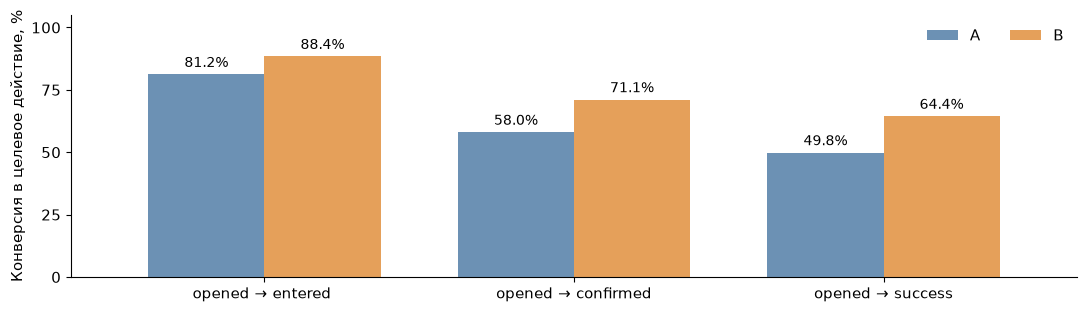

In [39]:
from matplotlib import pyplot as plt

# единые цвета и оформление графиков
colors = ['#6c91b4', '#e5a05a']
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

funnel = data \
    .groupby('group')[date_cols] \
    .count() \
    .reindex(['A', 'B']) \
    .T

funnel_percent = funnel.div(funnel.iloc[0], axis=1) * 100

ax = funnel_percent.iloc[1:] \
    .rename(index={
        'step2_entered': 'opened → entered ',
        'step3_confirmed': 'opened → confirmed',
        'step4_success': 'opened → success'
    }) \
    .plot.bar(figsize=(11, 3.2), color=colors, width=0.75, rot=0)

ax.set_ylim(0, 105)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel('Конверсия в целевое действие, %')
ax.set_xlabel('')
ax.legend(['A', 'B'], loc='upper right', ncol=2, frameon=False)
ax.grid(False)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.show()


In [40]:
# конверсия из предыдущего шага в следующий, %
funnel.div(funnel.shift(1)).iloc[1:] \
    .mul(100) \
    .round(2) \
    .rename(index={
        'step2_entered': 'opened → entered',
        'step3_confirmed': 'entered → confirmed',
        'step4_success': 'confirmed → success'
    })


group,A,B
opened → entered,81.18,88.38
entered → confirmed,71.44,80.40
confirmed → success,85.88,90.62


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">В группе B выше конверсия на каждом переходе.</p>
    <p style="font-size: 14px;">Посмотрим, сохраняется ли разница конверсий в течение эксперимента. Отнесём попытку к периоду по дате открытия формы. Последний период, 29-30 апреля, содержит только два дня.</p>
</div>

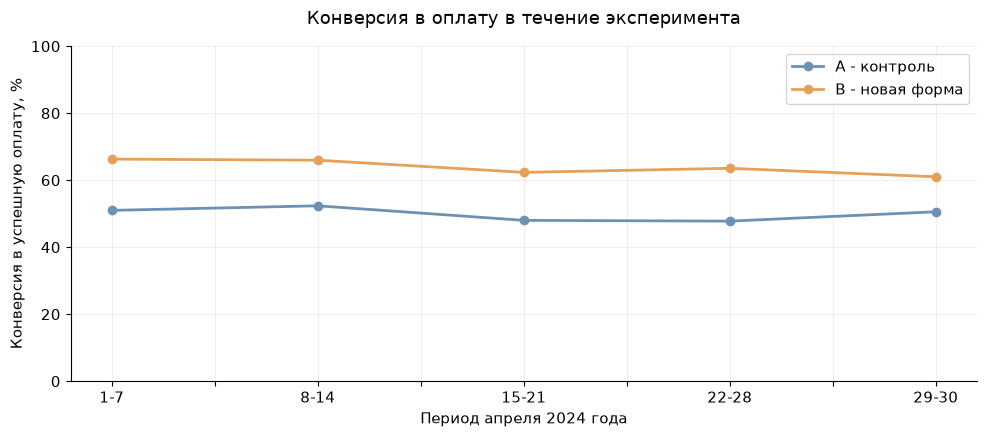

group,A,B
period,,
1-7,50.98,66.29
8-14,52.35,65.96
15-21,48.00,62.32
22-28,47.77,63.54
29-30,50.56,61.00


In [41]:
weekly_metrics = data \
    .assign(period=pd.cut(
        data['step1_opened'].dt.day,
        bins=[0, 7, 14, 21, 28, 30],
        labels=['1-7', '8-14', '15-21', '22-28', '29-30']
    )) \
    .groupby(['period', 'group'], observed=True) \
    .agg(
        success=('step4_success', 'count'),
        opened=('step1_opened', 'count')
    ) \
    .assign(CR=lambda x: x.success * 100.0 / x.opened)

weekly_cr = weekly_metrics['CR'].unstack('group')[['A', 'B']]
ax = weekly_cr.plot(figsize=(10, 4.5), marker='o', color=colors, linewidth=2)
ax.set_ylim(0, 100)
ax.set_xlabel('Период апреля 2024 года')
ax.set_ylabel('Конверсия в успешную оплату, %')
ax.set_title('Конверсия в оплату в течение эксперимента', pad=16)
ax.legend(['A - контроль', 'B - новая форма'])
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

weekly_cr.round(2)


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">На графике видим динамику: наблюдаемая конверсия в группе B выше во всех пяти периодах.</p>
    <p style="font-size: 14px;">Дополнительно сравним конверсии по городам и платформам. Посмотрим, сохраняется ли разница между A и B внутри каждого сегмента. Метрику считаем так же: число успешных оплат / число открытий формы. Также выведем число пользователей и попыток, чтобы видеть размер сегментов.</p>
</div>

In [42]:
# конверсии по городам, %
city_metrics = data \
    .assign(city=data['city'].fillna('Не указан')) \
    .groupby(['city', 'group']) \
    .agg(
        users=('user_id', 'nunique'),
        success=('step4_success', 'count'),
        opened=('step1_opened', 'count')
    ) \
    .assign(CR=lambda x: x.success * 100.0 / x.opened)

city_metrics.round({'CR': 2})


users  success  opened      CR
city      group                                
Москва    A        287      235     501   46.91
          B        306      369     567   65.08
Не указан A          1        1       1  100.00
Регион    A        268      234     461   50.76
          B        245      263     428   61.45
СПб       A        194      181     344   52.62
          B        199      238     356   66.85

In [43]:
# конверсии по платформам, %
device_metrics = data \
    .groupby(['device_type', 'group']) \
    .agg(
        users=('user_id', 'nunique'),
        success=('step4_success', 'count'),
        opened=('step1_opened', 'count')
    ) \
    .assign(CR=lambda x: x.success * 100.0 / x.opened)

device_metrics.round({'CR': 2})


users  success  opened     CR
device_type group                               
android     A        406      349     713  48.95
            B        369      425     666  63.81
ios         A        344      302     594  50.84
            B        381      445     685  64.96

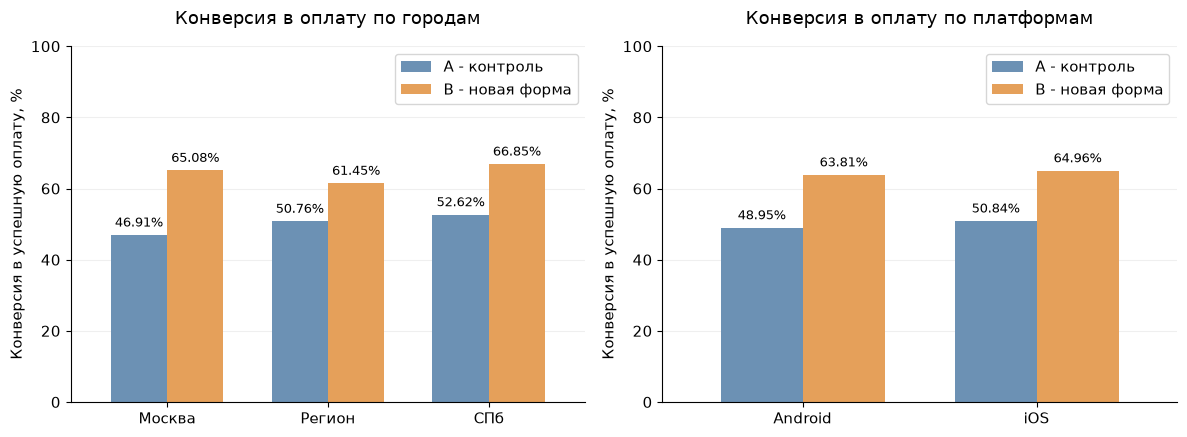

In [44]:
# на графике сравниваем сегменты, в которых есть обе группы
city_cr = city_metrics['CR'].unstack('group')[['A', 'B']].dropna()
device_cr = device_metrics['CR'].unstack('group')[['A', 'B']]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
city_cr.plot.bar(ax=axes[0], color=colors, rot=0, width=0.7)
device_cr.rename(index={'android': 'Android', 'ios': 'iOS'}) \
    .plot.bar(ax=axes[1], color=colors, rot=0, width=0.7)

axes[0].set_title('Конверсия в оплату по городам', pad=16)
axes[1].set_title('Конверсия в оплату по платформам', pad=16)

for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_xlabel('')
    ax.set_ylabel('Конверсия в успешную оплату, %')
    ax.legend(['A - контроль', 'B - новая форма'])
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.2f%%', padding=4, fontsize=9)

plt.tight_layout()
plt.show()


In [45]:
# разница конверсий B - A, п.п.
pd.concat({
    'Город': city_cr,
    'Платформа': device_cr
}, names=['Сегмент', 'Значение']) \
    .assign(diff=lambda x: x['B'] - x['A']) \
    .round(2)


group                   A      B   diff
Сегмент   Значение                     
Город     Москва    46.91  65.08  18.17
          Регион    50.76  61.45  10.69
          СПб       52.62  66.85  14.24
Платформа android   48.95  63.81  14.87
          ios       50.84  64.96  14.12

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Конверсия в оплату в тестовой группе выше, чем в контрольной: <b>64.4%  против 49.8% </b>
</p>
    <p style="font-size: 14px;">В срезах по всем городам/платформам конверсия в оплату в группе B также выше.</p> 
    <p style="font-size: 14px;">Проверим, является ли изменение метрики статистически значимыми.</p>
</div>

<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">3. Статистическая проверка гипотезы по ключевой метрике</b>
</div>

Гипотезы:

**H₀:** Конверсия в оплату из открытия формы одинакова в группах A и B.


**H₁:** Конверсия в оплату из открытия формы различается в группах A и B.

Факт оплаты - бинарный признак: 1, если оплата на ШАГЕ 4 была, и 0, если нет.
Поскольку платежи пользователя - зависимы,  то для сравнения конверсий в группах будем использовать **линеаризацию с t-тестом Уэлча**:

1) в результате линеаризации получаем одно числовое значение для каждого пользователя вместо нескольких платежей.
2) каждому пользователю соответствует одно значение, объединяющее все его попытки; предполагаем независимость наблюдений между пользователями.
3) при достаточно большом количестве независимых пользователей средние значения можно приближённо сравнивать с помощью t-теста благодаря ЦПТ.
4) t-тест Уэлча не требует равенства дисперсий в сравниваемых группах и равенства объемов выборок.


В каждой группе по 750 пользователей. Для приближённого вывода используем ЦПТ и предполагаем независимость пользователей и корректное случайное распределение по группам.

In [46]:
import numpy as np
from scipy import stats

def check_linearization(a, b):
    """a, b - таблицы пользователей групп A и B с колонками success и opened."""
    coef = a.success.sum() / a.opened.sum()
    a_lin = a.success - coef * a.opened
    b_lin = b.success - coef * b.opened

    _, pvalue = stats.ttest_ind(a_lin, b_lin, equal_var=False)
    delta = b_lin.mean() - a_lin.mean()
    return pvalue, delta


user_attempts = data \
    .groupby(['group', 'user_id']) \
    .agg(
        success=('step4_success', 'count'),
        opened=('step1_opened', 'count')
    ) \
    .reset_index()

a = user_attempts[user_attempts['group'] == 'A']
b = user_attempts[user_attempts['group'] == 'B']

pvalue, delta = check_linearization(a, b)
print('p-value < 0.001' if pvalue < 0.001 else f'p-value = {pvalue:.4f}')

alpha = 0.05  # уровень значимости
if pvalue < alpha:
    print('Отклоняем H₀: обнаружено статистически значимое различие конверсий между группами A и B.')
else:
    print('Не отклоняем H₀: статистически значимого различия конверсий между группами A и B не обнаружено.')


p-value < 0.001
Отклоняем H₀: обнаружено статистически значимое различие конверсий между группами A и B.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">По результатам теста с линеаризацией получили <b>p-value &lt; 0,001</b>, что меньше уровня значимости <b>0,05</b>.</p>
    <p style="font-size: 14px;">Нулевую гипотезу отклоняем: между контрольной и тестовой группами <b>обнаружено статистически значимое различие конверсий в оплату</b>.</p>
</div>


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Дополнительно построим 95% доверительный интервал разницы конверсий, чтобы оценить величину возможного эффекта и точность полученной оценки.</p>
</div>

In [47]:
# 95% доверительный интервал разницы конверсий B - A (дельта метод)
cr_a = a.success.sum() / a.opened.sum()
cr_b = b.success.sum() / b.opened.sum()

a_cr_lin = cr_a + (a.success - cr_a * a.opened) / a.opened.mean()
b_cr_lin = cr_b + (b.success - cr_b * b.opened) / b.opened.mean()

ci_low, ci_high = stats.ttest_ind(b_cr_lin, a_cr_lin, equal_var=False) \
    .confidence_interval(confidence_level=1 - alpha)

print(f'Разница CR (B - A) = {(cr_b - cr_a) * 100:.2f} п.п.')
print(f'95% доверительный интервал: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.')


Разница CR (B - A) = 14.59 п.п.
95% доверительный интервал: [10.88; 18.30] п.п.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <p style="font-size: 14px;">Конверсия в группе B выше, чем в группе A, на <b>14,59 п.п.</b></p>
    <p style="font-size: 14px;">95% доверительный интервал разницы конверсий B - A по дельта-методу: <b>от 10,88 до 18,30 п.п.</b> Интервал не включает ноль и целиком находится выше него. Это подтверждает вывод, что <b>конверсия в группе B статистически значимо выше</b>.</p>
</div>


<div style="background-color: #fce4c2; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">4. Результаты и рекомендации</b>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">Результаты анализа</b>
    <p style="font-size: 14px;">После очистки данных в анализе осталось <b>1500 уникальных пользователей с попытками оплаты, по 750 в группах A и B</b>, и <b>2658 попыток оплаты</b>. Это число пользователей, представленных в очищенной таблице платежей, а не общее число участников эксперимента. Исключили попытку без user_id и пользователя 1010, у которого расходились группы. Некорректный возраст заменили на пропуски. Пользователей с ошибкой в возрасте или пропуском города сохранили.</p>
    <p style="font-size: 14px;">В группе A успешно завершилась <b>651 из 1307 попыток оплаты</b>, в группе B - <b>870 из 1351</b>. Конверсия составила <b>49,81% в A</b> и <b>64,40% в B</b>. В тестовой группе она выше на <b>14,59 п.п.</b>, или на <b>29,29% относительно контрольной группы</b>.</p>
    <p style="font-size: 14px;">По результатам теста с линеаризацией получили <b>p-value &lt; 0,001</b>, что меньше уровня значимости <b>0,05</b>. Нулевую гипотезу отклоняем: <b>обнаружено статистически значимое различие конверсии из оформления в оплату</b>.</p>
    <p style="font-size: 14px;">95% доверительный интервал разницы конверсий B - A: <b>от 10,88 до 18,30 п.п.</b> Интервал не включает ноль и целиком находится выше него. Это подтверждает вывод, что конверсия в группе B выше.</p>
    <p style="font-size: 14px;">По графикам видно, что конверсия в B выше на всех переходах воронки и во всех рассмотренных периодах апреля. Улучшение наблюдается в течение всего теста.</p>
    <p style="font-size: 14px;">Дополнительно сравнили города и платформы. В каждом сравниваемом сегменте конверсия в B выше, чем в A. Разница на Android составляет <b>14,87 п.п.</b>, на iOS - <b>14,12 п.п.</b>; по городам - <b>от 10,69 до 18,17 п.п.</b> Это дополнительное наблюдение в пользу запуска, но значимость различий между сегментами отдельно не проверялась.</p>
</div>

<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <b style="font-size: 14px;">Рекомендации продуктовой команде</b>
    <p style="font-size: 14px;">Рекомендую не принимать окончательное решение о полном запуске до подтверждения корректности механизма распределения пользователей (user_id идут в основном подряд: 1001–1750 в группе A и 1751–2500 в группе B). Возможно, это особенность выгрузки, но нужно подтвердить, что распределение было случайным.</p>
    <ul>
        <li style="font-size: 14px;">Если корректность рандомизации подтверждена, результаты эксперимента позволяют рекомендовать поэтапное внедрение новой формы с мониторингом ключевых и защитных метрик.</li>
        <li style="font-size: 14px;">Если группы формировались неслучайно, необходимо провести повторный A/B-тест с корректной рандомизацией.</li>
    </ul>
</div>
